# Target code

## Load the file using the file path

In [1]:
import pandas as pd
data = pd.read_csv("C:/Users/anhha/Documents/colon/colon.csv", 
                   na_values=["", " "]) 
data

,rownames,id,study,rx,sex,age,obstruct,perfor,adhere,nodes,status,differ,extent,surg,node4,time,etype
0,1,1,1,Lev+5FU,1,43,0,0,0,5.0,1,2.0,3,0,1,1521,2
1,2,1,1,Lev+5FU,1,43,0,0,0,5.0,1,2.0,3,0,1,968,1
2,3,2,1,Lev+5FU,1,63,0,0,0,1.0,0,2.0,3,0,0,3087,2
3,4,2,1,Lev+5FU,1,63,0,0,0,1.0,0,2.0,3,0,0,3087,1
4,5,3,1,Obs,0,71,0,0,1,7.0,1,2.0,2,0,1,963,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1853,1854,927,1,Lev,1,76,0,0,1,1.0,1,3.0,3,0,0,851,1
1854,1855,928,1,Lev+5FU,0,48,1,0,0,4.0,0,2.0,3,1,1,2072,2
1855,1856,928,1,Lev+5FU,0,48,1,0,0,4.0,0,2.0,3,1,1,2072,1
1856,1857,929,1,Lev,0,66,1,0,0,1.0,0,2.0,3,0,0,1820,2


## Filter the data with etype==2

In [2]:
filtered_data = data[data['etype']==2]
filtered_data

,rownames,id,study,rx,sex,age,obstruct,perfor,adhere,nodes,status,differ,extent,surg,node4,time,etype
0,1,1,1,Lev+5FU,1,43,0,0,0,5.0,1,2.0,3,0,1,1521,2
2,3,2,1,Lev+5FU,1,63,0,0,0,1.0,0,2.0,3,0,0,3087,2
4,5,3,1,Obs,0,71,0,0,1,7.0,1,2.0,2,0,1,963,2
6,7,4,1,Lev+5FU,0,66,1,0,0,6.0,1,2.0,3,1,1,293,2
8,9,5,1,Obs,1,69,0,0,0,22.0,1,2.0,3,1,1,659,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1848,1849,925,1,Lev+5FU,1,71,0,0,1,4.0,0,2.0,3,0,0,1875,2
1850,1851,926,1,Lev,0,72,0,0,0,1.0,0,2.0,3,0,0,2154,2
1852,1853,927,1,Lev,1,76,0,0,1,1.0,1,3.0,3,0,0,1018,2
1854,1855,928,1,Lev+5FU,0,48,1,0,0,4.0,0,2.0,3,1,1,2072,2


## 2. Calculate the median survival time.

In [3]:
from lifelines import KaplanMeierFitter
from lifelines.utils import median_survival_times

clean_data = filtered_data

T = clean_data["time"]
E = (clean_data['status'] == 1)

# Now fit will work
kmf = KaplanMeierFitter()
kmf.fit(T, event_observed=E)
median_ci = median_survival_times(kmf.confidence_interval_)
print(kmf.median_survival_time_)

2552.0


## 3. Create a graph of KM estimated survival functions stratified by node4, adding 95% confidence intervals and coloring the 2 functions.

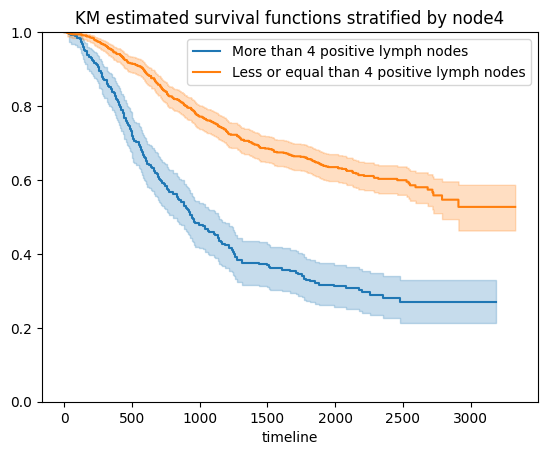

In [4]:
from matplotlib import pyplot as plt

ax = plt.subplot(111)

node4 = (clean_data["node4"] == 1)

kmf.fit(T[node4], event_observed=E[node4], label="More than 4 positive lymph nodes")
kmf.plot_survival_function(ax=ax)

kmf.fit(T[~node4], event_observed=E[~node4], label="Less or equal than 4 positive lymph nodes")
kmf.plot_survival_function(ax=ax)
ax.set_ylim(0, 1)
plt.title("KM estimated survival functions stratified by node4");

## 4. Use the log-rank test for rx variable.

In [5]:
from lifelines.statistics import multivariate_logrank_test

results = multivariate_logrank_test(
    clean_data['time'], 
    clean_data['rx'],  
    clean_data['status']
)
results.print_summary()
p_value = results.p_value

print(f"p-value: {p_value}")

p-value: 0.00290434799758616


## 5. Use a Cox proportional hazards model to estimate hazard ratios for the effects of rx, age, sex, nodes.

In [6]:
from lifelines import CoxPHFitter
import pandas as pd

cols = ['time', 'status', 'rx', 'age', 'sex', 'node4']
clean_data = clean_data[cols].dropna().copy()
clean_data['event'] = (clean_data['status'] == 1).astype(int)

clean_data['rx'] = pd.Categorical(clean_data['rx'])

cph = CoxPHFitter()
cph.fit(
    df=clean_data,
    duration_col='time',
    event_col='event',
    formula="Q('rx') + Q('age') + Q('sex') + Q('node4')"
)
cph.print_summary(decimals=6)

<lifelines.CoxPHFitter: fitted with 929 total observations, 477 right-censored observations>
             duration col = 'time'
                event col = 'event'
      baseline estimation = breslow
   number of observations = 929
number of events observed = 452
   partial log-likelihood = -2878.253734
         time fit was run = 2026-08-15 13:39:14 UTC

---
                        coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                               
Q('rx')[T.Lev+5FU] -0.343633  0.709189  0.120023       -0.578875       -0.108391            0.560529            0.897276
Q('rx')[T.Obs]      0.039722  1.040522  0.110367       -0.176593        0.256037            0.838121            1.291801
Q('age')            0.006117  1.006136  0.004035       -0.001792        0.014025            0.998210            1.014124
Q('sex')            0.027971  1.028366  0.094370       -0.156991        0.212934            0.854712            1.237303
Q('node4')          0.973631  2.647541  0.097277        0.782972        1.164291            2.187965            3.203650

                     cmp to         z        p  -log2(p)
covariate                                               
Q('rx')[T.Lev+5FU] 0.000000 -2.863049 0.004196  7.896820
Q('rx')[T.Obs]     0.000000  0.359909 0.718915  0.476107
Q('age')           0.000000  1.515932 0.129537  2.948569
Q('sex')           0.000000  0.296400 0.766925  0.382843
Q('node4')         0.000000 10.008852   <5e-07 75.925524
---
Concordance = 0.638459
Partial AIC = 5766.507467
log-likelihood ratio test = 103.875834 on 5 df
-log2(p) of ll-ratio test = 66.751750

## Harrell's C-statistic

In [7]:
import pandas as pd
from lifelines import CoxPHFitter

cph = CoxPHFitter()
cph.fit(filtered_data, duration_col='time', event_col='status',
        formula='age + sex + node4 + C(rx)')

print(cph.concordance_index_)

0.6384587824032382


## Plot the survival curves of male patient age of 70, treatment with Lev+5FU, with more than 4 number of lymph nodes.

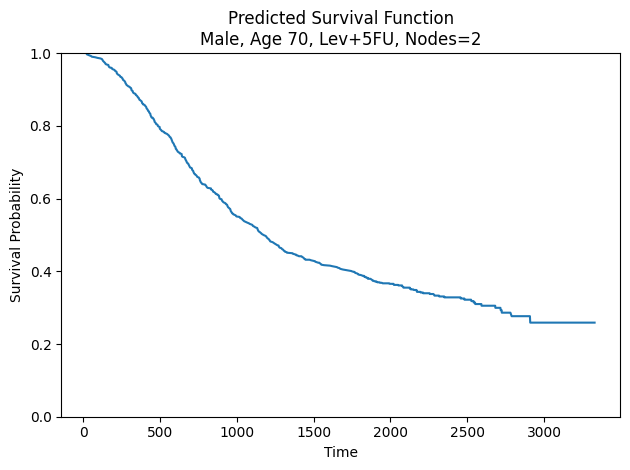

In [8]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Define patient profile
rx_categories = clean_data['rx'].cat.categories  # ['Lev', 'Lev+5FU', 'Obs']

pattern1 = pd.DataFrame({
    'age': [70.0],
    'sex': [1.0],
    'node4': [1.0],
    'rx': pd.Categorical(['Lev+5FU'], categories=rx_categories)
})

# 2. Predict survival function
surv_func = cph.predict_survival_function(pattern1)

# 3. Plot using lifelines' built-in .plot()
ax = surv_func.plot(
    title='Predicted Survival Function\nMale, Age 70, Lev+5FU, Nodes=2',
    legend=False
)
ax.set_xlabel('Time')
ax.set_ylim(0, 1)
ax.set_ylabel('Survival Probability')
plt.tight_layout()
plt.show()

## Last observed survival probability

In [9]:
surv_func.iloc[-1, 0]

np.float64(0.2587838842625787)

## Assessing the proportional hazards assumption with a statistical test.

In [11]:
from lifelines import CoxPHFitter
from lifelines.statistics import proportional_hazard_test

results = proportional_hazard_test(cph, clean_data)

results.print_summary(decimals=4, model="untransformed variables")

## 9. Extended Cox model

In [18]:
import pandas as pd
from lifelines import CoxTimeVaryingFitter

cutpoint = 1095
df = filtered_data.copy()

before = df[df['time'] <= cutpoint].copy()
before['start'], before['stop'], before['event'] = 0, before['time'], before['status']

after = df[df['time'] > cutpoint].copy()
seg1 = after.copy()
seg1['start'], seg1['stop'], seg1['event'] = 0, cutpoint, 0                  
seg2 = after.copy()
seg2['start'], seg2['stop'], seg2['event'] = cutpoint, seg2['time'], seg2['status'] 

df_split = pd.concat([before, seg1, seg2], ignore_index=True).sort_values(['id', 'start'])

df_split['hv1'] = df_split['node4'] * (df_split['start'] < cutpoint).astype(int)
df_split['hv2'] = df_split['node4'] * (df_split['start'] >= cutpoint).astype(int)

df_split['rx'] = pd.Categorical(df_split['rx'], categories=['Obs', 'Lev', 'Lev+5FU'])
df_split = pd.get_dummies(df_split, columns=['rx'], drop_first=True)

model_df = df_split[['id','start','stop','event','age','sex','hv1','hv2','rx_Lev','rx_Lev+5FU']]

ctv = CoxTimeVaryingFitter()
ctv.fit(model_df, id_col='id', event_col='event', start_col='start', stop_col='stop', show_progress=True)
ctv.print_summary(decimals=6)

Iteration 1: norm_delta = 5.52e-01, step_size = 0.9500, log_lik = -2930.19165, newton_decrement = 6.10e+01, seconds_since_start = 0.1
Iteration 2: norm_delta = 7.68e-02, step_size = 0.9500, log_lik = -2878.84927, newton_decrement = 1.72e+00, seconds_since_start = 0.2
Iteration 3: norm_delta = 4.38e-03, step_size = 0.9500, log_lik = -2877.12688, newton_decrement = 5.41e-03, seconds_since_start = 0.3
Iteration 4: norm_delta = 2.35e-04, step_size = 1.0000, log_lik = -2877.12148, newton_decrement = 1.40e-05, seconds_since_start = 0.4
Iteration 5: norm_delta = 1.49e-08, step_size = 1.0000, log_lik = -2877.12147, newton_decrement = 5.01e-14, seconds_since_start = 0.6
Convergence completed after 5 iterations.


<lifelines.CoxTimeVaryingFitter: fitted with 1555 periods, 929 subjects, 452 events>
         event col = 'event'
number of subjects = 929
 number of periods = 1555
  number of events = 452
partial log-likelihood = -2877.121467
  time fit was run = 2026-07-24 13:38:04 UTC

---
                coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                       
age         0.006110  1.006129  0.004038       -0.001805        0.014025            0.998197            1.014123
sex         0.029474  1.029913  0.094374       -0.155495        0.214443            0.855992            1.239172
hv1         1.070038  2.915490  0.116377        0.841942        1.298133            2.320871            3.662453
hv2         0.749946  2.116887  0.181225        0.394751        1.105142            1.484015            3.019652
rx_Lev     -0.040860  0.959964  0.110365       -0.257172        0.175452            0.773235            1.191785
rx_Lev+5FU -0.378571  0.684840  0.118894       -0.611599       -0.145542            0.542483            0.864554

             cmp to         z        p  -log2(p)
covariate                                       
age        0.000000  1.513072 0.130261  2.940519
sex        0.000000  0.312315 0.754801  0.405832
hv1        0.000000  9.194557   <5e-07 64.525752
hv2        0.000000  4.138199 0.000035 14.802110
rx_Lev     0.000000 -0.370223 0.711216  0.491640
rx_Lev+5FU 0.000000 -3.184090 0.001452  9.427647
---
Partial AIC = 5766.242934
log-likelihood ratio test = 106.140368 on 6 df
-log2(p) of ll-ratio test = 66.050075

## 10. AFT model

In [28]:
import pandas as pd
import numpy as np
from lifelines import WeibullAFTFitter

# Chuẩn bị dữ liệu
cols = ['time', 'status', 'rx', 'age', 'sex', 'node4']
clean_data = clean_data[cols].dropna().copy()
clean_data['event'] = (clean_data['status'] == 1).astype(int)
clean_data['rx'] = pd.Categorical(clean_data['rx'])

# Fit Weibull AFT model
aft = WeibullAFTFitter()
aft.fit(
    df=clean_data,
    duration_col='time',
    event_col='event',
    formula="Q('rx') + Q('age') + Q('sex') + Q('node4')"
)

aft.print_summary(decimals=6)

<lifelines.WeibullAFTFitter: fitted with 929 total observations, 477 right-censored observations>
             duration col = 'time'
                event col = 'event'
   number of observations = 929
number of events observed = 452
           log-likelihood = -4075.800459
         time fit was run = 2026-07-25 12:41:01 UTC

---
                                coef   exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
param   covariate                                                                                                                 
lambda_ Intercept           8.681058 5890.276593  0.256898        8.177546        9.184570         3560.109003         9745.588776
        Q('rx')[T.Lev+5FU]  0.346202    1.413689  0.114178        0.122418        0.569987            1.130226            1.768244
        Q('rx')[T.Obs]     -0.045236    0.955771  0.104702       -0.250449        0.159976            0.778451            1.173483
        Q('age')           -0.006092    0.993927  0.003846       -0.013629        0.001445            0.986464            1.001446
        Q('sex')           -0.030147    0.970303  0.089520       -0.205603        0.145309            0.814156            1.156397
        Q('node4')         -0.959399    0.383123  0.095955       -1.147468       -0.771330            0.317439            0.462398
rho_    Intercept           0.052615    1.054024  0.041839       -0.029387        0.134617            0.971040            1.144099

                             cmp to         z        p   -log2(p)
param   covariate                                                
lambda_ Intercept          0.000000 33.791783   <5e-07 829.101256
        Q('rx')[T.Lev+5FU] 0.000000  3.032129 0.002428   8.685806
        Q('rx')[T.Obs]     0.000000 -0.432049 0.665705   0.587044
        Q('age')           0.000000 -1.584128 0.113165   3.143505
        Q('sex')           0.000000 -0.336759 0.736299   0.441637
        Q('node4')         0.000000 -9.998381   <5e-07  75.772928
rho_    Intercept          0.000000  1.257566 0.208549   2.261544
---
Concordance = 0.638559
AIC = 8165.600917
log-likelihood ratio test = 111.843729 on 5 df
-log2(p) of ll-ratio test = 72.342375